In [1]:
import matplotlib.pyplot as plt
import numpy as np

import word2vec as w2v


In [2]:
corpus = """
The cat sat on the mat. The dog sat on the rug.
The cat chased the mouse. The dog chased the ball.
The mouse ran under the table. The ball rolled under the chair.
The cat slept on the chair. The dog slept on the mat.
The small cat watched the bird. The small dog watched the mouse.
The bird sat in the tree. The mouse hid under the rug.

The girl played with the cat. The boy played with the dog.
The girl threw the ball. The dog chased the ball across the garden.
The boy watched the bird. The bird flew across the garden.
The cat walked through the garden. The dog ran through the garden.
The girl sat under the tree. The boy sat beside the girl.
The cat slept beside the girl. The dog slept beside the boy.

The cat ate food from the bowl. The dog ate food from the bowl.
The girl filled the bowl with water. The boy gave food to the dog.
The cat drank water from the bowl. The dog drank water after playing.
The mouse found food under the table. The bird found food in the garden.
The girl put the bowl on the mat. The boy put the ball on the rug.
The cat watched the mouse eat. The dog watched the cat drink.

The big dog ran to the tree. The small dog ran to the chair.
The big cat jumped onto the table. The small cat jumped onto the chair.
The mouse ran away from the cat. The bird flew away from the dog.
The boy called the dog. The girl called the cat.
The dog walked toward the boy. The cat walked toward the girl.
The boy and the girl played in the garden. The cat and the dog rested under the tree.
"""


In [3]:
sentences = w2v.split_sentences(corpus)
tokenized_sentences = [w2v.tokenize(s) for s in sentences]

rng = np.random.default_rng(42)
indices = rng.permutation(len(tokenized_sentences))

train_end = int(0.70 * len(indices))
val_end = int(0.85 * len(indices))


train_sentences = [tokenized_sentences[i] for i in indices[:train_end]]
val_sentences = [tokenized_sentences[i] for i in indices[train_end:val_end]]
test_sentences = [tokenized_sentences[i] for i in indices[val_end:]]

# Build vocab from train data only
word_to_id, id_to_word, word_counts = w2v.build_vocab(train_sentences, min_count=1)

# Evaluate vocabulary coverage on the validation sentences
token_coverage, type_coverage = w2v.vocab_coverage(val_sentences, word_to_id)

print(f"Val token coverage: {token_coverage*100:.2f}%")
print(f"Val type coverage: {type_coverage*100:.2f}%")

# Evaluate vocabulary coverage on the test sentences
token_coverage, type_coverage = w2v.vocab_coverage(test_sentences, word_to_id)

print(f"Test token coverage: {token_coverage*100:.2f}%")
print(f"Test type coverage: {type_coverage*100:.2f}%")

# Use the same vocab to generate pairs for all three sets
train_pairs = w2v.generate_pairs(train_sentences, word_to_id, window_size=2)
val_pairs = w2v.generate_pairs(val_sentences, word_to_id, window_size=2)
test_pairs = w2v.generate_pairs(test_sentences, word_to_id, window_size=2)

print(f"Training pairs: {len(train_pairs)}")
print(f"Val pairs: {len(val_pairs)}")
print(f"Test pairs: {len(test_pairs)}")


Val token coverage: 90.48%
Val type coverage: 80.95%
Test token coverage: 90.38%
Test type coverage: 88.00%
Training pairs: 654
Val pairs: 102
Test pairs: 128


In [4]:
LEARNING_RATE = 0.01
EMBEDDING_DIM = 3
EPOCHS = 100
RESTORE_BEST_WEIGHTS = False

model = w2v.Word2Vec(word_to_id, id_to_word, EMBEDDING_DIM, LEARNING_RATE, seed=42)

train_loss_history, val_loss_history = model.train(
    train_pairs, val_pairs, epochs=EPOCHS, restore_best_weights=RESTORE_BEST_WEIGHTS
)

print(f"Last epoch training loss: {train_loss_history[-1]:.4f}")
print(f"Last epoch validation loss: {val_loss_history[-1]:.4f}")


Last epoch training loss: 2.9827
Last epoch validation loss: 2.9420


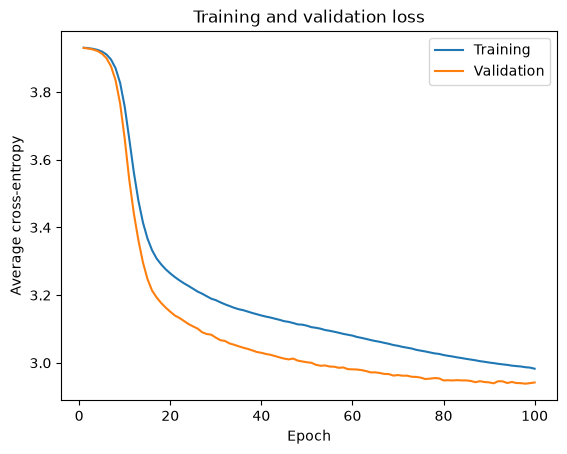

In [5]:
epochs = range(1, len(train_loss_history) + 1)

plt.plot(epochs, train_loss_history, label="Training")
plt.plot(epochs, val_loss_history, label="Validation")
plt.xlabel("Epoch")
plt.ylabel("Average cross-entropy")
plt.title("Training and validation loss")
plt.legend()
plt.show()


In [6]:
test_loss = model.evaluate(test_pairs)
print(f"Test loss: {test_loss:.4f}")


Test loss: 2.9780
